# Week 6b.1: Agentic RAG

The support agent already decides *whether* to search. What it has never decided is **how hard to search**.

Every policy question so far ran the same pipeline. A one-line lookup and a two-part question about shipping and refunds both got the same treatment.

Today the agent will pick a retrieval strategy to match the question, and then decide whether what came back is enough. The three strategies are things we have already built: search once, rewrite first, or plan the question into steps.

<img src="figures/adaptive.png" width="800">

Two decisions, one inside the other.
- The agent decides **where to look** by picking a tool, which is what it has done since Week 4. 
- Inside `search_policy`, a second decision picks **how hard to look**:
    - one search of the question as asked, 
    - one search of a reworded question, or 
    - a plan with a search per part.

Then it grades what came back, and if it fell short it repairs whichever thing broke. 
- A thin search was worded badly, so it gets reworded. 
- A thin plan was missing a step, so it gets another one.

In [2]:
from dotenv import load_dotenv
import os

load_dotenv()
assert os.getenv("GOOGLE_API_KEY"), "No GOOGLE_API_KEY found."
print("API key loaded")

API key loaded


## 0. Model Setup

Execute one of the following to define the model.

In [15]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:4b", reasoning=False)

In [3]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-5-nano")

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

Pick the same embedding model you used in Week 5.

In [ ]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

In [4]:
from langchain_ollama import OllamaEmbeddings

embeddings = OllamaEmbeddings(model="qwen3-embedding:0.6b")

In [ ]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(
    model="liquid/lfm-2.5-embedding-350m:free",
    base_url="https://openrouter.ai/api/v1",
    api_key=os.environ["OPENROUTER_API_KEY"],
    check_embedding_ctx_length=False,
)

In [ ]:
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings

embeddings = NVIDIAEmbeddings(model="nvidia/nemotron-3-embed-1b")

## 1. Running Example

Three questions requiring different strategies:
- Direct Retrieval
- Query transformation (rewrite)
- Plan (multiple steps)

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.vectorstores import InMemoryVectorStore

policy = open("husky_policy.md").read()
chunks = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=0).split_text(policy)
store = InMemoryVectorStore.from_texts(chunks, embeddings)

print(f"{len(chunks)} chunks indexed")

6 chunks indexed


In [6]:
EASY = "What are your support hours?"
VAGUE = "When do I actually get my money back?"
MULTI = ("I ordered on Saturday and want to return it. "
         "When does it ship, and how long until I see the refund?")

for q in (EASY, VAGUE, MULTI):
    hits = store.similarity_search(q, k=2)
    print(f"\n{q}")
    for h in hits:
        print("   ", " ".join(h.page_content.split())[:88])


What are your support hours?
    Approved warranty claims are fulfilled with a replacement unit of the same model, or an 
    Orders placed after 2pm ET ship the following business day. Orders placed on a weekend s

When do I actually get my money back?
    # Husky Tech Customer Policy ## 1. Returns ### 1.1 Standard return window Items purchase
    Return shipping is free for orders over $50. For orders under $50, a $6.99 return shippi

I ordered on Saturday and want to return it. When does it ship, and how long until I see the refund?
    # Husky Tech Customer Policy ## 1. Returns ### 1.1 Standard return window Items purchase
    Return shipping is free for orders over $50. For orders under $50, a $6.99 return shippi


One search is right for the first, which lands on section 4 immediately.

The second asks about refunds without using the word the policy uses, so it is worth rewriting before searching.

The third needs two searches, and no rewriting of a single query will get both halves.

Running one pipeline over all three is wrong in both directions. It wastes calls on the easy one and gives up on the hard one.

## 2. Adaptive RAG

One model call that looks at the question and says how much retrieval it needs. 

This is the idea in [Adaptive-RAG](https://arxiv.org/abs/2403.14403): 

- classify the query, then run the cheapest approach that can answer it.

In [11]:
from typing import Literal
from pydantic import BaseModel, Field


class Strategy(BaseModel):
    """How much retrieval this question needs."""

    reasoning: str = Field(
        description="What the question is asking for, and whether the policy "
                    "would use the same words the customer used")
    choice: Literal["direct", "transform", "plan"] = Field(
        description="direct: one search of the customer's own words will find it. "
                    "transform: one search is enough but the wording needs fixing first. "
                    "plan: the question has separate parts needing separate searches")


assessor = model.with_structured_output(Strategy)

ASSESS_PROMPT = """A customer asked: {question}

It will be answered from a short written policy covering returns, shipping,
warranty and support hours. The policy is searched one question at a time and
returns the two passages closest in meaning to whatever is asked.

How much retrieval does this question need?"""

In [12]:
for q in (EASY, VAGUE, MULTI):
    decision = assessor.invoke(ASSESS_PROMPT.format(question=q))
    print(f"{decision.choice:10} {q[:62]}")

direct     What are your support hours?
direct     When do I actually get my money back?
direct     I ordered on Saturday and want to return it. When does it ship


## 3. State

We'll use the same fields as before and add `strategy` from the assessor and `steps` for when the strategy is `plan`.

In [19]:
import operator
from typing import Annotated, TypedDict


class RetrievalState(TypedDict):
    question: str
    strategy: str                               # direct, transform, or plan
    query: str                                  # what we search with
    steps: list                                 # only used by the plan strategy
    documents: Annotated[list, operator.add]
    new_searches: int                              # how many the last attempt added
    grade: str
    missing: str
    attempts: int

## 4. The strategies

Three strategies for the agent to choose from:
- direct response
- `rewrite_query`
- `make_plan` with `execute`

In [16]:
K = 2
MAX_ATTEMPTS = 3

TRANSFORM_PROMPT = """A customer asked: {question}

It will be used to search a written policy, and the policy may not use the words
the customer used. Rewrite it as a plain question aimed at the rule that settles
it. Reply with the question only."""

REWRITE_PROMPT = """A search over a policy document did not return what was needed.

Customer question: {question}
Search just tried: {query}
What is still missing: {missing}

Write a different question to search with, aimed at the part that is missing.
Ask it as a plain question in a full sentence. Do not write a list of keywords.
Reply with the question only."""

PLAN_PROMPT = """A customer asked: {question}

The policy is searched one question at a time, and a search returns the two
passages closest in meaning to whatever is asked.

Break this into the separate searches needed to answer it. Each step is one
plain question. Keep it to the fewest steps that cover the question."""

REPLAN_PROMPT = """A customer asked: {question}

These searches were already run:
{already}

Still missing: {missing}

Write the additional searches needed. Do not repeat a search already run."""

GRADE_PROMPT = """A customer asked: {question}

Retrieved policy passages:

{context}

Do these passages contain the policy rules needed to answer this question?
If a rule is referred to but not stated here, it is missing.

Judge the passages, not the customer. The customer may not have mentioned every
detail about their situation, and that is not something retrieval can fix."""

In [17]:
class Plan(BaseModel):
    """The searches needed to answer the customer."""

    steps: list[str] = Field(
        description="Each step is one question to search the policy with")


class Grade(BaseModel):
    """Whether the retrieved passages answer the customer's question."""

    reasoning: str = Field(
        description="Name the rule that would settle this question, then say "
                    "whether it appears in the passages above")
    sufficient: bool = Field(
        description="True only if the passages contain every rule needed to answer")
    missing: str = Field(
        description="If not sufficient, what is missing, in a few words")


planner = model.with_structured_output(Plan)
grader = model.with_structured_output(Grade)

In [20]:
def rewrite_query(state: RetrievalState) -> dict:
    if state.get("missing"):
        revised_prompt = REWRITE_PROMPT.format(
            question=state["question"],
            query=state.get("query") or state["question"],
            missing=state["missing"])
    else:
        revised_prompt = TRANSFORM_PROMPT.format(question=state["question"])

    new_query = model.invoke(revised_prompt).text.strip()
    return {"query": new_query}


def make_plan(state: RetrievalState) -> dict:
    if state.get("missing") and state.get("steps"):
        already = "\n".join(f"- {step}" for step in state["steps"])
        plan_prompt = REPLAN_PROMPT.format(question=state["question"],
                                           already=already,
                                           missing=state["missing"])
    else:
        plan_prompt = PLAN_PROMPT.format(question=state["question"])

    plan = planner.invoke(plan_prompt)
    return {"steps": plan.steps}


def retrieve(state: RetrievalState) -> dict:
    query = state.get("query") or state["question"]
    existing_docs = set(state.get("documents") or [])
    new_docs = [h.page_content for h in store.similarity_search(query, k=K)
                if h.page_content not in existing_docs]

    return {"documents": new_docs, "query": query,
            "new_searches": len(new_docs),
            "attempts": state.get("attempts", 0) + 1}


def execute(state: RetrievalState) -> dict:
    existing_docs = set(state.get("documents") or [])
    new_docs = []
    for step in state["steps"]:
        for hit in store.similarity_search(step, k=K):
            if hit.page_content not in existing_docs | set(new_docs):
                new_docs.append(hit.page_content)

    return {"documents": new_docs, "new_searches": len(new_docs),
            "attempts": state.get("attempts", 0) + 1}


def grade_documents(state: RetrievalState) -> dict:
    augmented_query = GRADE_PROMPT.format(question=state["question"],
                                context="\n\n".join(state["documents"]))

    verdict = grader.invoke(augmented_query)
    return {"grade": "sufficient" if verdict.sufficient else "insufficient",
            "missing": verdict.missing}

### New nodes
<img src="figures/adaptive.png" width="800">


How do we assess the question? 

Which strategy to start with, and whether to go round again?

In [21]:
def assess(state: RetrievalState) -> dict:
    if state.get("strategy"):        # demo only; handed one with the question, to start it on a chosen rung
        return {}

    assess_prompt = ASSESS_PROMPT.format(question=state["question"])

    decision = assessor.invoke(assess_prompt)
    return {"strategy": decision.choice}

In [22]:
def choose_strategy(state: RetrievalState) -> Literal["retrieve", "rewrite_query", "make_plan"]:
    if state["strategy"] == "direct":
        return "retrieve"
    if state["strategy"] == "transform":
        return "rewrite_query"
    return "make_plan"

In [23]:
def decide(state: RetrievalState) -> Literal["rewrite_query", "make_plan", "__end__"]:
    if state["grade"] == "sufficient":
        return "__end__"
    if state["attempts"] >= MAX_ATTEMPTS:
        return "__end__"
    if state["new_searches"] == 0:          # the last search found nothing we did not have
        return "__end__"
    if state["strategy"] == "plan":      # a plan that missed a part needs another step,
        return "make_plan"               # not a reworded version of the same search
    return "rewrite_query"

### Understanding Adaptive RAG
Both `rewrite_query` and `make_plan` are reached two ways.
- When entering from `assess`, neither will have a `missing` yet, so one rewrites the customer's wording and the other writes a first plan. 
- When entering from `grade_documents`, both will know what fell short, so one aims the search at the gap and the other adds the step that covers it.

That is why there are two ways back rather than one. 
- A single search that came back thin was worded badly. 
- A plan that came back thin was missing a step, and rewording one of its searches will not add it. 
- Each branch returns to the node it came in through.

`decide` has a third exit as well:
- If the last search returned nothing we did not already have, going round again cannot change the evidence, only the verdict on it.

## 5. The adaptive retriever

In [24]:
from langgraph.graph import StateGraph, START, END

retrieval = StateGraph(RetrievalState)
retrieval.add_node("assess", assess)
retrieval.add_node("rewrite_query", rewrite_query)
retrieval.add_node("make_plan", make_plan)
retrieval.add_node("retrieve", retrieve)
retrieval.add_node("execute", execute)
retrieval.add_node("grade_documents", grade_documents)

retrieval.add_edge(START, "assess")
retrieval.add_conditional_edges("assess", choose_strategy)
retrieval.add_edge("rewrite_query", "retrieve")
retrieval.add_edge("make_plan", "execute")
retrieval.add_edge("retrieve", "grade_documents")
retrieval.add_edge("execute", "grade_documents")
retrieval.add_conditional_edges("grade_documents", decide)

adaptive_search = retrieval.compile()

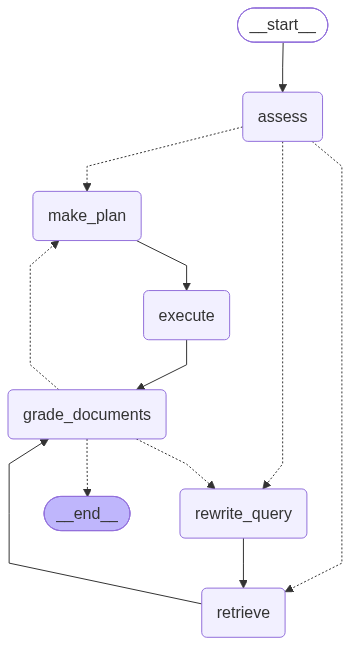

In [25]:
from IPython.display import Image, display

display(Image(adaptive_search.get_graph().draw_mermaid_png()))

Three ways in, one way out. 
- Every question enters at `assess` and leaves from `grade_documents`
- What happens in between is the agent's choice.

## 6. Watching it choose

In [26]:
def trace(question):
    print(question)
    for update in adaptive_search.stream({"question": question}, stream_mode="updates"):
        for node, change in update.items():
            if node == "assess":
                print(f"  strategy: {change['strategy']}")
            elif node == "rewrite_query":
                print(f"  rewrote to: {change['query']}")
            elif node == "make_plan":
                for step in change["steps"]:
                    print(f"  step: {step}")
            elif node in ("retrieve", "execute"):
                print(f"  {node}: {len(change['documents'])} new passages "
                      f"(attempt {change['attempts']})")
            elif node == "grade_documents":
                print(f"  grade: {change['grade']}")
    print()


for q in (EASY, VAGUE, MULTI):
    trace(q)

What are your support hours?
  strategy: transform
  rewrote to: What are the official hours of operation for support services?
  retrieve: 2 new passages (attempt 1)
  grade: sufficient

When do I actually get my money back?
  strategy: direct
  retrieve: 2 new passages (attempt 1)
  grade: insufficient
  rewrote to: What are the specific requirements and fees associated with returning an item to receive a refund?
  retrieve: 0 new passages (attempt 2)
  grade: insufficient

I ordered on Saturday and want to return it. When does it ship, and how long until I see the refund?
  strategy: transform
  rewrote to: What are the shipping timeline and refund confirmation periods for items ordered on Saturday?
  retrieve: 2 new passages (attempt 1)
  grade: insufficient
  rewrote to: What is the policy regarding refunds and returns for items ordered on a Saturday?
  retrieve: 2 new passages (attempt 2)
  grade: sufficient



Three questions, three different paths through the same graph.

The easy one spends one search and one grade. The multi-part one spends a plan, two searches and a grade. Nothing about the retriever changed between them, and neither did the code. The agent chose.


## 7. The Support Agent with Adaptive Retrieval

The entire compiled graph, `adaptive_search`, goes behind the `search_policy` tool, as before. 

The agent keeps its other tools and still decides for itself whether a question is about an order or about the policy.

In [27]:
from langchain.tools import tool

GAP_NOTE = """NOTE: after {attempts} searches the policy search did not find a rule
that settles this question ({missing}). The search coming up empty is not proof the
policy is silent, and a silent policy would not mean no. Do not tell the customer
that Husky Tech does or does not do this, and do not fill the gap from memory. This
is a question the tools cannot resolve."""


@tool
def search_policy(question: str) -> str:
    """Search the Husky Tech written policy and return the passages most relevant
    to a question. Use this for any question about returns, shipping, warranty or
    support hours. Returns policy text, not an answer: read it and decide."""
    
    result = adaptive_search.invoke({"question": question})
    
    passages = "\n\n---\n\n".join(d.strip() for d in result["documents"])

    if result["grade"] == "sufficient":
        return passages

    note = GAP_NOTE.format(attempts=result["attempts"],
                           missing=result["missing"][:120])
    return passages + "\n\n---\n\n" + note

In [28]:
from support_tools import (look_up_order, check_return_eligibility,
                            escalate_to_human, SYSTEM_PROMPT)
from langchain.messages import SystemMessage, HumanMessage
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

sys_msg = SystemMessage(content=SYSTEM_PROMPT)
TOOLS = [look_up_order, check_return_eligibility, search_policy, escalate_to_human]
model_with_tools = model.bind_tools(TOOLS)


def assistant(state: MessagesState) -> dict:
    return {"messages": [model_with_tools.invoke([sys_msg] + state["messages"])]}


builder = StateGraph(MessagesState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

support_agent = builder.compile(checkpointer=InMemorySaver())

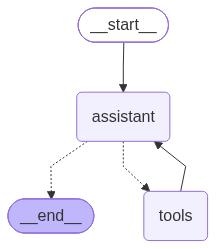

In [29]:
display(Image(support_agent.get_graph().draw_mermaid_png()))

Two levels of choosing now. The agent chooses **where** to look, by picking a tool. The retriever chooses **how hard** to look, by picking a strategy.

We leave the first one to tool calling on purpose. The model is good at it, and a question that needs an order and a rule will get both without us enumerating the combination.

In [30]:
def ask(question, thread):
    config = {"configurable": {"thread_id": thread}}
    result = support_agent.invoke(
        {"messages": [HumanMessage(content=question)]}, config)
    called = [tc["name"] for m in result["messages"]
              for tc in (getattr(m, "tool_calls", None) or [])]
    print(f"{question}\n  tools: {called}\n")
    print(result["messages"][-1].text)
    print("\n" + "-" * 70)


ask("Has order HT-1002 shipped yet?", "t1")

Has order HT-1002 shipped yet?
  tools: ['look_up_order']

Yes, your order HT-1002 for a mechanical keyboard has already been shipped. It was ordered on September 15th, with an expected delivery date of September 23rd.

----------------------------------------------------------------------


No retrieval at all. The agent read the question, saw an order id, and called the lookup. `assess` never ran, because `search_policy` was never called.

That is the cheapest case in Adaptive-RAG, and it costs nothing to get: the saving comes from a decision not to retrieve.

In [32]:
ask(MULTI, "t2")

I ordered on Saturday and want to return it. When does it ship, and how long until I see the refund?
  tools: ['search_policy']

Based on general policy, orders placed on weekends ship out the following Monday, and standard refunds are processed to the original payment method within 30 days of purchase, with final processing usually happening within 5 business days after we receive the returned item.

However, to give you specific details about your order's shipping date and eligibility, I will need your **Order ID**.

Could you please provide your Order ID so I can look up the status for you?

----------------------------------------------------------------------


Here the tool did run, and behind it `assess` chose `plan`.

In [ ]:
ask("I want to return order HT-1001, but the cable on it is fraying. "
    "Can I still send it back?", "t3")

## 8. What it costs

Every question now pays for one extra model call before any searching happens.

| question | assess | searches | grades | rewrites or plans |
|---|---|---|---|---|
| support hours | 1 | 1 | 1 | 0 |
| frayed cable | 1 | 1 | 1 | 1 |
| ship and refund | 1 | 2 | 1 | 1 |

The assessor earns that call back when it picks `direct` on a question that would otherwise have been rewritten, and loses it when it picks `direct` on a question that needed a plan.

Adaptive-RAG uses a small trained classifier here rather than the main model, for exactly this reason. A chooser has to be cheaper than the thing it is choosing between, or you have spent the saving on the decision.

### Decisions based on the readings

| | decides | using | where it is |
|---|---|---|---|
| [Adaptive-RAG](https://arxiv.org/abs/2403.14403) | how much retrieval the question needs | the question, before retrieving | `assess` |
| [Corrective RAG](https://arxiv.org/abs/2401.15884) | what to do with what came back | an evaluator, after retrieving | `grade_documents` and `decide` |

Both replace a fixed pipeline with a step that chooses. That is what makes retrieval agentic.

## 9. Adaptive effort with escalation

`assess` runs once. Whatever it picks, the graph is stuck with, and a question it misjudges gets the wrong strategy retried until the cap.

The obvious repair is to ask it again after a failure. 

Let's see whether that would help.

In [ ]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:4b", reasoning=False)
assessor = model.with_structured_output(Strategy)

In [33]:
MULTI = ("I ordered on Saturday and want to return it. "
         "When does it ship, and how long until I see the refund?")

picks = [assessor.invoke(ASSESS_PROMPT.format(question=MULTI)).choice for _ in range(4)]
print(picks)

['direct', 'direct', 'direct', 'direct']


In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

Whatever your model answers, it typically answers the same way four times.

That is the problem with asking again. `assess` is a function of the question, and the question has not changed between attempts. A model that reads it correctly keeps reading it correctly; a model that misreads it keeps misreading it. 

**Problem:**
- `assess` never sees the information that *is* new after a failed attempt

**So we will not ask again.** 
- Instead, put the strategies in order of how much work they do, and move up one level when the evidence falls short.

In [34]:
LADDER = ["direct", "transform", "plan"]

print(LADDER.index("direct"))

0


In [ ]:

def escalate(state: RetrievalState) -> dict:
    rung = LADDER.index(state["strategy"])
    return {"strategy": LADDER[rung + 1]}


def after_escalate(state: RetrievalState) -> Literal["rewrite_query", "make_plan"]:
    """escalate only ever moves up, so direct is not one of the places it can land."""
    return "rewrite_query" if state["strategy"] == "transform" else "make_plan"


def decide_with_ladder(state: RetrievalState) -> Literal["escalate", "make_plan", "__end__"]:
    if state["grade"] == "sufficient":
        return "__end__"
    if state["attempts"] >= MAX_ATTEMPTS:
        return "__end__"
    if state["new_searches"] == 0:
        return "__end__"
    if state["strategy"] != LADDER[-1]:
        return "escalate"
    return "make_plan"          # already at the top, so repair in place

### Building the escalating agent
We will wire the same nodes with the new decision

To watch it recover from a wrong guess, we'll pass `strategy` in with the question.

In [36]:
ladder = StateGraph(RetrievalState)
ladder.add_node("assess", assess)
ladder.add_node("escalate", escalate)
ladder.add_node("rewrite_query", rewrite_query)
ladder.add_node("make_plan", make_plan)
ladder.add_node("retrieve", retrieve)
ladder.add_node("execute", execute)
ladder.add_node("grade_documents", grade_documents)

ladder.add_edge(START, "assess")
ladder.add_conditional_edges("assess", choose_strategy)
ladder.add_conditional_edges("escalate", after_escalate)
ladder.add_edge("rewrite_query", "retrieve")
ladder.add_edge("make_plan", "execute")
ladder.add_edge("retrieve", "grade_documents")
ladder.add_edge("execute", "grade_documents")
ladder.add_conditional_edges("grade_documents", decide_with_ladder)

escalating_search = ladder.compile()

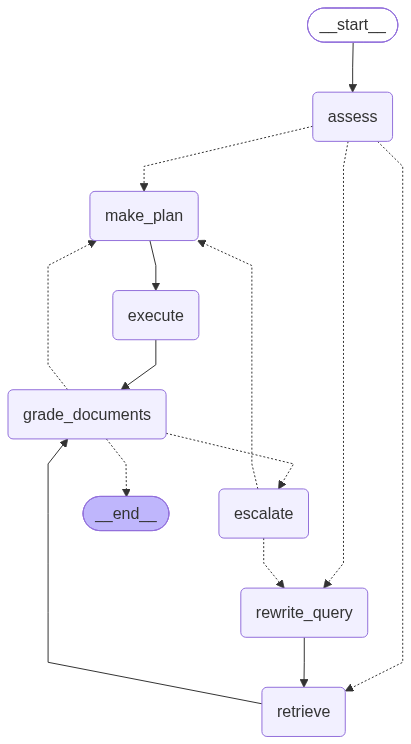

In [37]:
display(Image(escalating_search.get_graph().draw_mermaid_png()))

In [38]:
print(f"question: {MULTI}")
for update in escalating_search.stream({"question": MULTI, "strategy": "direct"},
                                       stream_mode="updates"):
    for node, change in update.items():
        if node == "escalate":
            print(f"  escalate -> {change['strategy']}")
        elif node == "rewrite_query":
            print(f"  rewrote: {change['query'][:62]}")
        elif node == "make_plan":
            for step in change["steps"]:
                print(f"  step: {step}")
        elif node in ("retrieve", "execute"):
            print(f"  {node}: +{change['new_searches']} (attempt {change['attempts']})")
        elif node == "grade_documents":
            print(f"  grade: {change['grade']}")

question: I ordered on Saturday and want to return it. When does it ship, and how long until I see the refund?
  retrieve: +2 (attempt 1)
  grade: insufficient
  escalate -> transform
  rewrote: How long does shipping typically take for returns?
  retrieve: +1 (attempt 2)
  grade: insufficient
  escalate -> plan
  step: When does my order placed on Saturday ship?
  step: How long until I see the refund after returning it?
  execute: +1 (attempt 3)
  grade: sufficient


It starts on the wrong step, finds the evidence short, and climbs rather than retrying.

Two things this costs. Every rung is more model calls than the one below, so a system that escalates often has spent the saving that made `assess` worth having. And the signal it climbs on is weak: `insufficient` does not say whether the strategy was too cheap or the policy is silent. Ask it about gift wrapping and it will climb all three rungs to learn what the first one already knew.

The exit on `new_searches == 0` is what stops that being unbounded.

## 10. Adding a diagnosis mechanism

Both costs come from the same place. `grade_documents` returns one bit, `sufficient` or not, and one bit cannot tell "search harder" from "stop looking". So the ladder climbs on every failure, including the ones where climbing cannot help.

The information to tell them apart is already in front of the grader: the passages. 

**Solution:**
- Ask the grader to say *why* they fall short, and route on that answer instead of moving up one rung.

To make this work, we need to change two things. 
- `Grade` will return a verdict with four values, and `decide` will act upon it. 


In [39]:
DIAGNOSE_PROMPT = """A customer asked: {question}

Retrieved policy passages:

{context}

Do these passages contain the policy rules needed to answer this question?
If a rule is referred to but not stated here, it is missing.

If they do not, say which of these it is:
- absent: the policy has nothing on this topic. The passages are about other things.
- wrong_words: the policy covers this, but these passages landed next to the rule
  rather than on it.
- incomplete: part of the question is settled here and another part is not.

Judge the passages, not the customer. The customer may not have mentioned every
detail about their situation, and that is not something retrieval can fix."""


class Diagnosis(BaseModel):
    """Whether the passages answer the question, and if not, why not."""

    reasoning: str = Field(
        description="Name the rule that would settle this question, then say "
                    "whether it appears in the passages above")
    verdict: Literal["sufficient", "absent", "wrong_words", "incomplete"] = Field(
        description="sufficient: every rule needed is here. "
                    "absent: the policy does not cover this. "
                    "wrong_words: it does, but the search missed it. "
                    "incomplete: one part is answered and another is not")
    missing: str = Field(
        description="If not sufficient, what is missing, in a few words")


diagnoser = model.with_structured_output(Diagnosis)


def diagnose(state: RetrievalState) -> dict:
    diagnose_prompt = DIAGNOSE_PROMPT.format(question=state["question"],
                                             context="\n\n".join(state["documents"]))

    verdict = diagnoser.invoke(diagnose_prompt)
    return {"grade": verdict.verdict, "missing": verdict.missing}

Each verdict has one place to go: 
- `sufficient` and `absent` both end the search, one because the answer is in hand and the other because there is nothing to find. 
- `incomplete` means a part of the question has not been searched for yet, so it goes to the planner. 
- `wrong_words` means the search was aimed at the right rule and missed, so it goes to the rewriter.

In [40]:
def decide_by_diagnosis(state: RetrievalState) -> Literal["rewrite_query", "make_plan", "__end__"]:
    if state["grade"] in ("sufficient", "absent"):   # done, or nothing to find
        return "__end__"
    if state["attempts"] >= MAX_ATTEMPTS:
        return "__end__"
    if state["new_searches"] == 0:
        return "__end__"
    if state["grade"] == "incomplete":    # a part is unanswered, and it needs its own search
        return "make_plan"
    return "rewrite_query"                # wrong_words: the same search, better aimed

### Revising the graph
 `escalate` is no longer needed, because the diagnosis says where to go and there is no longer a rung to climb.

In [41]:
diagnosing = StateGraph(RetrievalState)
diagnosing.add_node("assess", assess)
diagnosing.add_node("rewrite_query", rewrite_query)
diagnosing.add_node("make_plan", make_plan)
diagnosing.add_node("retrieve", retrieve)
diagnosing.add_node("execute", execute)
diagnosing.add_node("diagnose", diagnose)

diagnosing.add_edge(START, "assess")
diagnosing.add_conditional_edges("assess", choose_strategy)
diagnosing.add_edge("rewrite_query", "retrieve")
diagnosing.add_edge("make_plan", "execute")
diagnosing.add_edge("retrieve", "diagnose")
diagnosing.add_edge("execute", "diagnose")
diagnosing.add_conditional_edges("diagnose", decide_by_diagnosis)

diagnosing_search = diagnosing.compile()

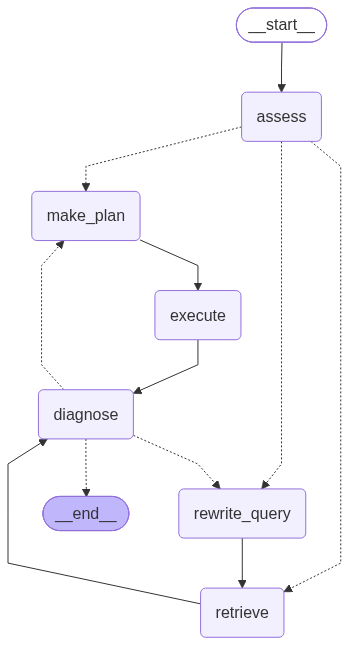

In [42]:
display(Image(diagnosing_search.get_graph().draw_mermaid_png()))

In [43]:
def trace_diagnosis(question, strategy=None):
    inputs = {"question": question}
    if strategy:
        inputs["strategy"] = strategy        # start it on a chosen rung
    print(f"question: {question}")
    for update in diagnosing_search.stream(inputs, stream_mode="updates"):
        for node, change in update.items():
            if node == "assess" and change:
                print(f"  strategy: {change['strategy']}")
            elif node == "rewrite_query":
                print(f"  rewrote: {change['query'][:62]}")
            elif node == "make_plan":
                for step in change["steps"]:
                    print(f"  step: {step}")
            elif node in ("retrieve", "execute"):
                print(f"  {node}: +{change['new_searches']} (attempt {change['attempts']})")
            elif node == "diagnose":
                note = "" if change["grade"] == "sufficient" else f"  ({change['missing']})"
                print(f"  diagnose: {change['grade']}{note}")
    print()

First, the question the ladder would have climbed all three rungs on.

In [44]:
trace_diagnosis("Do you offer gift wrapping?")

question: Do you offer gift wrapping?
  strategy: direct
  retrieve: +2 (attempt 1)
  diagnose: absent  (There is nothing about gift wrapping in these passages.)



One search, one verdict, done. The ladder spent three attempts to learn what the first one knew.

Now the question from the ladder run, handed `direct` on purpose as the ladder was.

In [45]:
trace_diagnosis(MULTI, strategy="direct")

question: I ordered on Saturday and want to return it. When does it ship, and how long until I see the refund?
  retrieve: +2 (attempt 1)
  diagnose: incomplete  (shipping dates)
  step: When does my order placed on Saturday ship?
  step: How long does it take to see a refund after I return an item?
  execute: +2 (attempt 2)
  diagnose: incomplete  ("How long until I see the refund" requires knowing the exact arrival date, which depends on shipping speed (standard 3-5 days vs expedited) and processing time details not explicitly combined into a total duration in the text. The text only states refunds are issued within 5 business days of ARRIVAL.)
  step: search "how long until refund after delivery arrives"
  step: search "refund timeline based on expedited vs standard shipping"
  execute: +0 (attempt 3)
  diagnose: incomplete  (none)



The ladder climbs one rung per failure, so a two-part question handed `direct` pays for `transform` before it can reach `plan`, and a reworded search for a two-part question is still one search. The diagnosis reads `incomplete` on the first pass and goes straight to the planner. The cost no longer depends on how wrong the starting rung was.

One limitation:
- `absent` is still a model's judgement, and it is being asked to tell "I did not find it" from "it is not there". A search that missed the rule cannot know it missed, so `absent` will sometimes be wrong in the same way `insufficient` was. Treat it as a cheap exit the agent can act on, with the customer's own words and the other tools still available, rather than as the final word.

## 11. Three graphs

| graph | what happens after a failed search | use it when |
|---|---|---|
| adaptive | retry the strategy `assess` chose, with a reworded query or an extra plan step | `assess` is reliable on your questions and most failures are a wording miss |
| ladder | move up one rung to a more expensive strategy | `assess` misjudges often and the grader cannot say why |
| diagnosis | the grader says why, and that verdict picks the next node or stops | the grader can tell "not here" from "missed it" from "half answered" |

The adaptive graph is the cheapest per question and the one to measure first. If it is good enough, stop there.

The ladder is the safe move when the only signal you have is "not enough". It is the right default for a corpus or a question mix you do not know well yet, and it is what the DADA2 agent uses.

The diagnosis is the cheapest on hard questions and the only one that stops early on a question the policy cannot answer. It rests on the grader's judgement, so check that judgement on a labelled set before you trust it.

Which one you need depends on your questions, and you do not know that until you measure.

## 12. Things to try

1. Ask something where you disagree with `assess`. Print `decision.reasoning` to see what it thought the question was asking, and change `ASSESS_PROMPT` until it chooses what you would.

2. Make `assess` always return `direct`, then run all three questions. Which answers get worse, and by how much? That is the value of the chooser, measured.

3. `decide` sends the plan strategy to `replan` and everything else to `rewrite_query`. Change it so that everything goes to `rewrite_query`, then run a question that takes the plan branch and falls short. What does the reworded search do that the extra step did not, and which answer is better?

4. `assess` runs on the question the *agent* passed to the tool, not the customer's words. Print both and see how often they differ.

5. Add a fourth strategy, `none`, for questions the policy cannot answer at all, and have it return straight to the agent without searching. What goes in the prompt so it is not chosen too often?

6. The cheap-looking version of `absent` is a floor on the similarity score: if the best passage scores low, nothing is close, so stop. Print the top score for `VAGUE` and for "Do you offer gift wrapping?" and see which one is lower. What does that tell you about using the score as the signal?


In [ ]:
# your experiments here